In [35]:
from eo_flood_ops.fier import (
    reof, 
    find_hydro_mode, 
    combine_eof_hydro, 
    plot_fier_diagnostics, 
    download_gfm,
    synthesize,
    calibrate_synthesis_threshold, 
)

from eo_flood_ops.general_utils import skill

import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

In [ ]:
# # Stacking flood maps into an xarray dataset
# folder = Path(r"P:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\classified_events")
# files = sorted(folder.glob("hoian_*.tif"))

# if not files:
#     raise FileNotFoundError(f"No TIFF files found in {folder}")

# floodmaps = []
# for file in files:
#     timestamp = pd.to_datetime(
#         file.stem.replace("hoian_", "", 1),
#         format="%Y%m%dT%H%M%S",
#     )

#     with rasterio.open(file) as src:
#         data = src.read(1)
#         cols = range(src.width)
#         rows = range(src.height)
#         x_coords, _ = rasterio.transform.xy(src.transform, 0, cols, offset="center")
#         _, y_coords = rasterio.transform.xy(src.transform, rows, 0, offset="center")

#         floodmap = xr.DataArray(
#             data,
#             dims=("y", "x"),
#             coords={"y": y_coords, "x": x_coords},
#             attrs={"crs": src.crs.to_string() if src.crs else None},
#         )

#     floodmaps.append(floodmap.expand_dims(time=[timestamp]))

# ds = xr.concat(floodmaps, dim="time").sortby("time").to_dataset(
#     name="floodmap"
# )

In [2]:
ds = download_gfm(
    bbox = (108.04893596289713, 15.767737848300511, 108.40355764191061,16.080839719319691),
    bands=["ensemble_water_extent"], 
    start_time=datetime(2022, 9, 1),
    end_time=datetime(2023, 8, 1),
    groupby="solar_day",
)

Found 641 GFM items.
All pixels are no data for band ensemble_water_extent on dates: ['2022-09-04T10:49:28.000000000' '2022-09-11T22:51:38.000000000'
 '2022-09-16T10:49:28.000000000' '2022-09-23T22:51:38.000000000'
 '2022-09-28T10:49:28.000000000' '2022-10-05T22:51:38.000000000'
 '2022-10-10T10:49:28.000000000' '2022-10-17T22:51:39.000000000'
 '2022-10-22T10:49:28.000000000' '2022-10-29T22:51:39.000000000'
 '2022-11-03T10:49:28.000000000' '2022-11-10T22:51:38.000000000'
 '2022-11-15T10:49:28.000000000' '2022-11-22T22:51:39.000000000'
 '2022-11-27T10:49:28.000000000' '2022-12-04T22:51:38.000000000'
 '2022-12-09T10:49:27.000000000' '2022-12-16T22:51:37.000000000'
 '2022-12-21T10:49:26.000000000' '2022-12-28T22:51:36.000000000'
 '2023-01-02T10:49:26.000000000' '2023-01-09T22:51:36.000000000'
 '2023-01-14T10:49:25.000000000' '2023-01-21T22:51:35.000000000'
 '2023-01-26T10:49:25.000000000' '2023-02-02T22:52:00.000000000'
 '2023-02-07T10:49:24.000000000' '2023-02-14T22:51:34.000000000'
 '202

In [3]:
threshold = 0.5
# if 50% of the pixels are no data VALUE 255 then exclude
# this is done because we have edge cases
ds = ds.where((ds["ensemble_water_extent"] != 255).sum(dim=["x", "y"]) / (ds["ensemble_water_extent"].shape[1] * ds["ensemble_water_extent"].shape[2]) > threshold, drop=True)

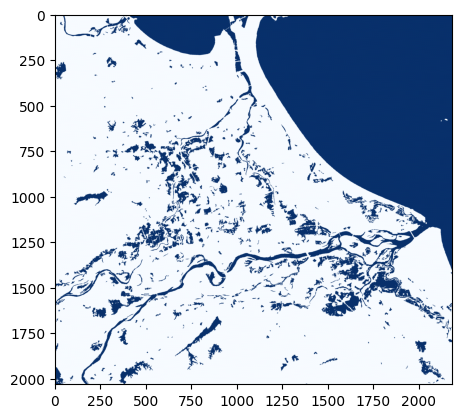

In [5]:
plt.imshow(ds["ensemble_water_extent"].sel(time="2022-10-15").values[0], cmap="Blues");

In [4]:
# Reading water level data from CSV and converting it to an xarray DataArray
waterlevels_fn = R"p:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\water_levels\Water_Level.csv"

df_water = pd.read_csv(waterlevels_fn, skiprows=[1])
df_water.rename(columns={df_water.columns[0]: "datetime"}, inplace=True)
df_water["datetime"] = pd.to_datetime(df_water["datetime"])

# convert timezone from GMT+7 to UTC
df_water["datetime"] = df_water["datetime"] - pd.Timedelta(hours=7)

# set index to datetime
df_water.set_index("datetime", inplace=True)
df_water.replace(-999, np.nan, inplace=True)

da_water = xr.DataArray(
    df_water.to_numpy(),
    coords={
        "time": ("time", df_water.index.to_numpy()),
        "site": ("site", df_water.columns.to_numpy()),
    },
    dims=("time", "site"),
    name="water_level",
)

# keep only ID 1,2, 6, 7
da_water = da_water.sel(site=["ID1", "ID2", "ID6", "ID7"])

# keep data for the same period as download_gfm()
gfm_start = ds["time"].min().values
gfm_end = ds["time"].max().values
da_water = da_water.sel(time=slice(gfm_start, gfm_end))

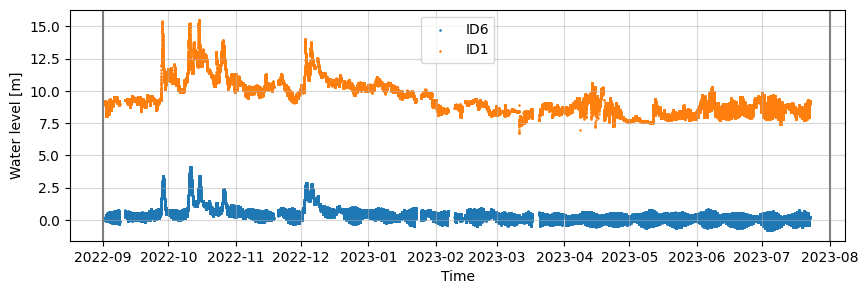

In [5]:
fig, ax = plt.subplots(figsize=(10, 3))

# Plot water level for site ID6 as points
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID6").values, label="ID6", s=0.7)
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID1").values, label="ID1", s=0.7)

ax.set_xlabel("Time")
ax.set_ylabel("Water level [m]")
ax.legend()
ax.grid(True, alpha=0.5)

# put vertical line in the gfm data download period
ax.axvline(datetime(2022, 9, 1), color="gray", label="GFM Download Start")
ax.axvline(datetime(2023, 8, 1), color="gray", label="GFM Download End")

In [6]:
# interpolate missing values in water level data
da_water = da_water.interpolate_na(dim="time", method="linear")

# check if there are still missing values
da_water.isnull().sum(dim="time")

<xarray.DataArray 'water_level' (site: 4)> Size: 32B
array([0, 0, 0, 0])
Coordinates:
  * site     (site) object 32B 'ID1' 'ID2' 'ID6' 'ID7'

In [7]:
eof_ds = reof(
    da=ds["ensemble_water_extent"],
    n_modes=5,
    # significance_test=True,
    y_dim= "y",
    x_dim= "x",
)

Performing REOF analysis using the first 5 modes...


In [8]:
hydro_modes = find_hydro_mode(
    ds_eof=eof_ds,
    da_hydro=da_water,
    r_thrd= 0.4,
    p_thrd= 0.1,
    time_dim= "time",
    site_dim= "site",
    warn_thrd=pd.Timedelta(hours=10),
    error_thrd=pd.Timedelta(days=1),
)

C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID1 is 0 days 22:46:03 away (at 2022-09-08T12:10:00.000000000). Requested timestamp: 2022-09-09T10:56:03.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID1 is 0 days 23:33:47 away (at 2023-01-24T22:10:00.000000000). Requested timestamp: 2023-01-23T22:36:13.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID2 is 0 days 22:46:03 away (at 2022-09-08T12:10:00.000000000). Requested timestamp: 2022-09-09T10:56:03.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID2 is 0 days 23:33:47 away (at 2023-01-24T22:10:00.000000000). Requested timestamp: 2023-01-23T22:36:13.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWar

In [9]:
eof_hydro = combine_eof_hydro(
    ds_eof=eof_ds,
    da_hydro=da_water,
    tpc_hydro_r=hydro_modes,
    time_dim="time",
    site_dim="site",
)

C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID6 is 0 days 22:46:03 away (at 2022-09-08T12:10:00.000000000). Requested timestamp: 2022-09-09T10:56:03.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID6 is 0 days 23:33:47 away (at 2023-01-24T22:10:00.000000000). Requested timestamp: 2023-01-23T22:36:13.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID1 is 0 days 22:46:03 away (at 2022-09-08T12:10:00.000000000). Requested timestamp: 2022-09-09T10:56:03.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWarning: Closest valid obs for ID1 is 0 days 23:33:47 away (at 2023-01-24T22:10:00.000000000). Requested timestamp: 2023-01-23T22:36:13.000000000
  warnings.warn(
C:\Users\tsiokano\git\EO-Flood-Ops\src\eo_flood_ops\fier.py:823: UserWar

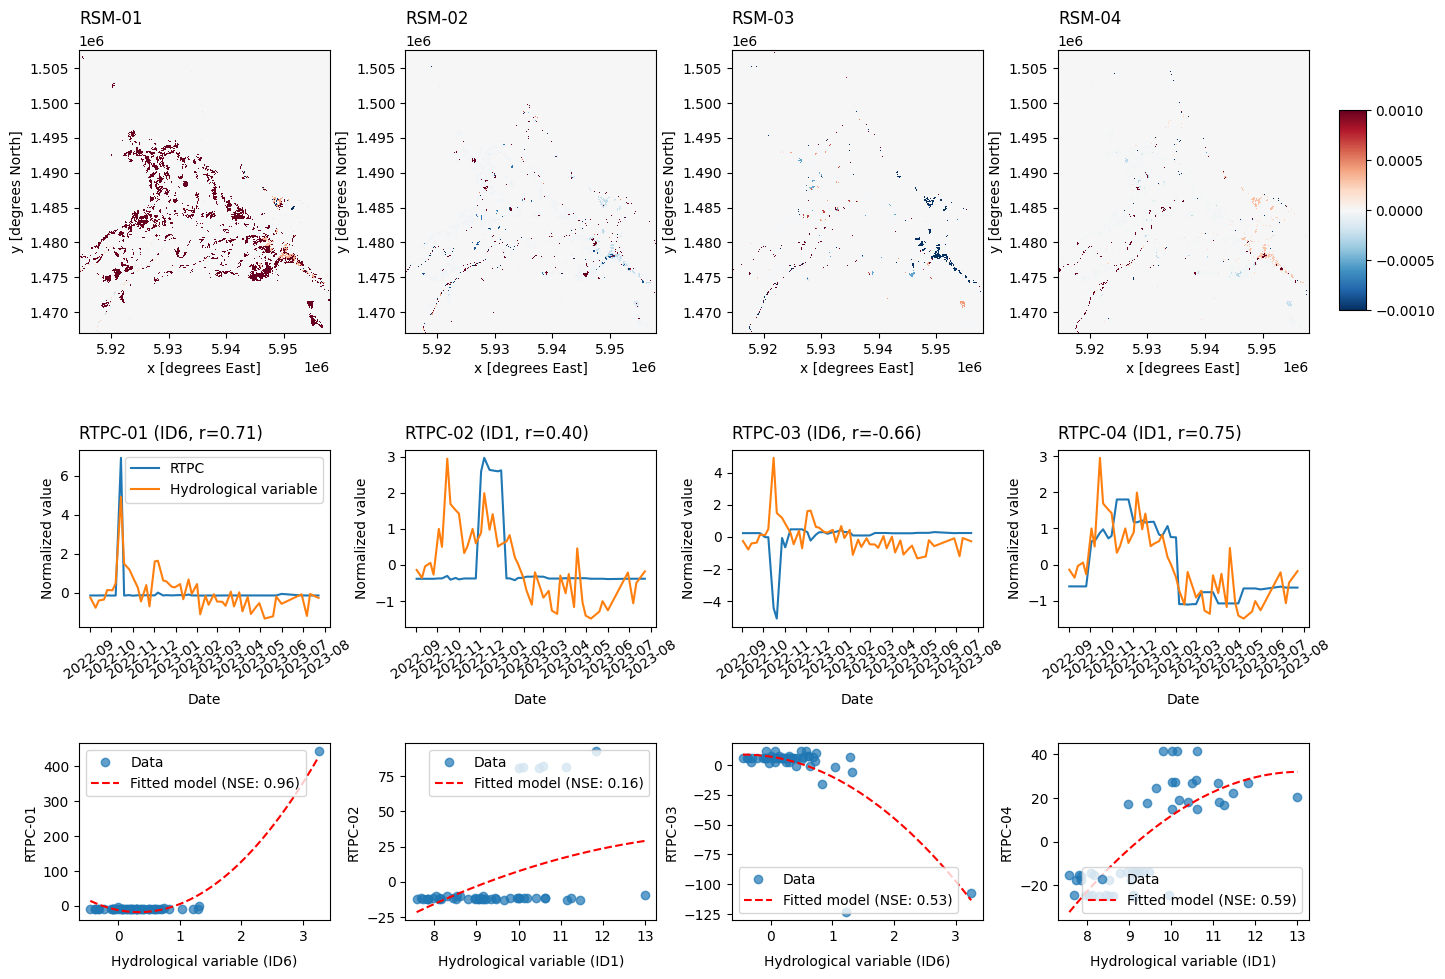

In [10]:
plot_fier_diagnostics(
    eof_hydro,
    spatial_vmin=-0.001,
    spatial_vmax=0.001,
);

In [12]:
eof_hydro

<xarray.Dataset> Size: 89MB
Dimensions:         (mode: 4, y: 2032, x: 2182, time: 49, degree: 3)
Coordinates:
  * mode            (mode) int64 32B 1 2 3 4
  * y               (y) float64 16kB 1.508e+06 1.508e+06 ... 1.467e+06 1.467e+06
  * x               (x) float64 17kB 5.914e+06 5.914e+06 ... 5.958e+06 5.958e+06
  * time            (time) datetime64[ns] 392B 2022-09-01T22:36:15 ... 2023-0...
  * degree          (degree) int64 24B 0 1 2
    site            (mode) object 32B 'ID6' 'ID1' 'ID6' 'ID1'
Data variables:
    spatial_modes   (mode, y, x) float32 71MB -1.333e-08 8.967e-10 ... 0.0 0.0
    temporal_modes  (mode, time) float32 784B -9.709 -9.709 ... -14.63 -14.63
    temporal_mean   (y, x) float32 18MB 0.0 0.0 0.0 1.0 1.0 ... 0.0 0.0 0.0 0.0
    explained_var   (mode) float32 16B 0.5738 0.1357 0.08269 0.07445
    hydro_var       (mode, time) float32 784B 0.19 -0.12 0.1 ... 8.1 8.79 9.18
    best_r          (mode) float64 32B 0.7149 0.4022 -0.6615 0.7489
    coefficients    (mode, degree) float32 48B -12.45 -35.08 ... 55.64 -2.126

In [ ]:
calibration = calibrate_synthesis_threshold(
    eof_hydro,
    ds["ensemble_water_extent"],
)

best_threshold = calibration["best_threshold"].item()
print(f"Best threshold: {best_threshold:.6g}")
print(f"Training water F1: {calibration['best_f1'].item():.4f}")

Best threshold: 0.471063
Training water F1: 0.9988


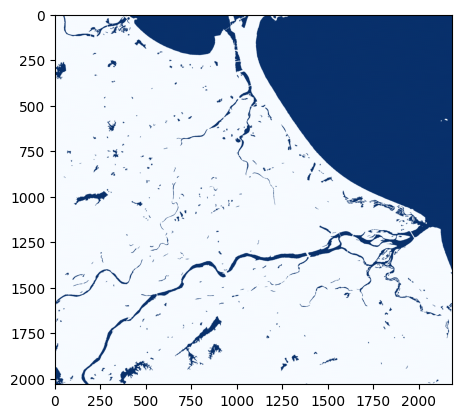

In [17]:
binary_image = synthesize(
    eof_hydro,
    da_water.sel(time="2022-10-13T20:00:00"),
    site_dim="site",
    threshold=best_threshold,
)

plt.imshow(binary_image.values, cmap="Blues");

In [29]:
q_now = da_water.sel(time="2023-06-01T00:00:00")

for mode in eof_hydro.mode.values:
    site = eof_hydro["site"].sel(mode=mode).item()
    q_value = q_now.sel(site=site).item()
    training_q = eof_hydro["hydro_var"].sel(mode=mode)
    coefficients = eof_hydro["coefficients"].sel(mode=mode).values
    predicted_pc = np.polynomial.polynomial.polyval(q_value, coefficients)

    print(
        f"mode={mode}, site={site}, q={q_value:.3f}, "
        f"training range=[{training_q.min().item():.3f}, {training_q.max().item():.3f}], "
        f"predicted PC={predicted_pc:.3f}"
    )

print(
    f"raw reconstruction range=[{pred_image.min().item():.3f}, "
    f"{pred_image.max().item():.3f}]"
)

mode=1, site=ID6, q=0.360, training range=[-0.450, 3.250], predicted PC=-18.293
mode=2, site=ID1, q=8.450, training range=[7.580, 13.000], predicted PC=-9.834
mode=3, site=ID6, q=0.360, training range=[-0.450, 3.250], predicted PC=2.903
mode=4, site=ID1, q=8.450, training range=[7.580, 13.000], predicted PC=-13.656
raw reconstruction range=[-0.181, 1.153]


In [19]:
# Reading water level data from CSV and converting it to an xarray DataArray
waterlevels_fn = R"p:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\water_levels\Water_Level.csv"

df_water = pd.read_csv(waterlevels_fn, skiprows=[1])
df_water.rename(columns={df_water.columns[0]: "datetime"}, inplace=True)
df_water["datetime"] = pd.to_datetime(df_water["datetime"])

# convert timezone from GMT+7 to UTC
df_water["datetime"] = df_water["datetime"] - pd.Timedelta(hours=7)

# set index to datetime
df_water.set_index("datetime", inplace=True)
df_water.replace(-999, np.nan, inplace=True)

da_water = xr.DataArray(
    df_water.to_numpy(),
    coords={
        "time": ("time", df_water.index.to_numpy()),
        "site": ("site", df_water.columns.to_numpy()),
    },
    dims=("time", "site"),
    name="water_level",
)

# keep only ID 1,2, 6, 7
da_water = da_water.sel(site=["ID1", "ID2", "ID6", "ID7"])

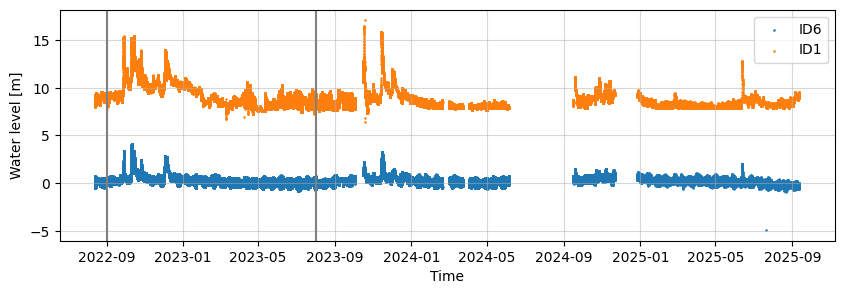

In [20]:
fig, ax = plt.subplots(figsize=(10, 3))

# Plot water level for site ID6 as points
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID6").values, label="ID6", s=0.7)
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID1").values, label="ID1", s=0.7)

ax.set_xlabel("Time")
ax.set_ylabel("Water level [m]")
ax.legend()
ax.grid(True, alpha=0.5)

# put vertical line in the gfm data download period
ax.axvline(datetime(2022, 9, 1), color="gray", label="GFM Download Start")
ax.axvline(datetime(2023, 8, 1), color="gray", label="GFM Download End")

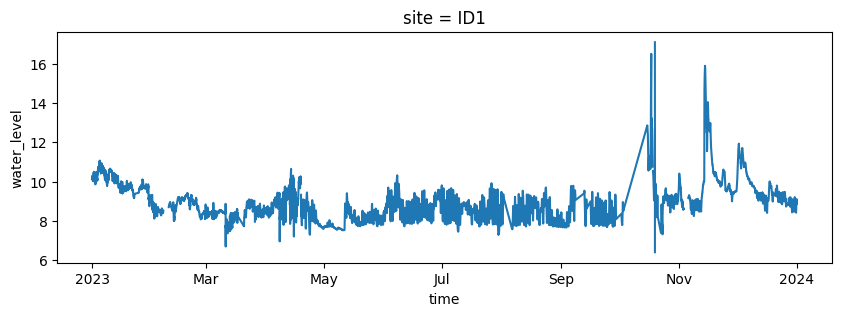

In [34]:
da_water.sel(site="ID1").sel(time="2023").plot(figsize=(10, 3))

In [29]:
da_water.sel(site="ID1").sel(time="2024-10").idxmax()

<xarray.DataArray 'time' ()> Size: 8B
array('2024-10-27T15:30:00.000000000', dtype='datetime64[ns]')
Coordinates:
    site     <U3 12B 'ID1'